# 📓 NB-03 — Jupyter Local + ROS 2: Controle Interativo
## ESP004 — Sistemas Autônomos Robóticos | PPGESP/IFBA 2026.2
**Autores:** Prof. Dr. José Alberto Díaz Amado · Prof. Dr. João Erivando Soares Marques

---
### Demonstração para Sala de Aula

Este notebook demonstra o **poder do Jupyter local com ROS 2**: controle interativo
do robô por sliders, visualização ao vivo de sensores e análise em tempo real.

| Seção | Conteúdo |
|-------|-----------|
| 3.1 | Painel de controle com widgets |
| 3.2 | Dashboard ao vivo: odometria + sensor |
| 3.3 | Gravação de bag e análise imediata |
| 3.4 | Pipeline completo: coletar → treinar → inferir |

> 🎓 **Para a aula:** Este notebook é projetado para rodar ao vivo enquanto o Gazebo corre em paralelo.

In [1]:
# ═══════════════════════════════════════════════════════════
# SETUP — Importações e inicialização única do rclpy
# Execute esta célula PRIMEIRO e apenas uma vez por sessão
# ═══════════════════════════════════════════════════════════
import rclpy, threading, time, math, random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import deque
from IPython.display import display, clear_output
import ipywidgets as widgets

# Inicializar ROS 2 uma única vez
if not rclpy.ok():
    rclpy.init()

print('✅ ROS 2 iniciado. Pode executar as próximas células.')

# Executor compartilhado para todos os nós deste notebook
import rclpy.executors
executor = rclpy.executors.MultiThreadedExecutor(num_threads=4)
exec_thread = None

✅ ROS 2 iniciado. Pode executar as próximas células.


/home/paulo/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


---
## 🎮 Seção 3.1 — Painel de Controle Interativo

In [2]:
# ═══════════════════════════════════════════════════════════
# PAINEL DE CONTROLE — Sliders para /cmd_vel
# Mova os sliders: o robô responde em tempo real!
# ═══════════════════════════════════════════════════════════
from rclpy.node import Node
from geometry_msgs.msg import Twist

class ControladorNode(Node):
    """Nó que publica Twist a partir de sliders Jupyter."""
    def __init__(self):
        super().__init__('controlador_jupyter')
        self._pub = self.create_publisher(Twist, '/cmd_vel', 10)
        self._vlin = 0.0
        self._vang = 0.0
        # Publicar a 10 Hz independente dos widgets
        self.create_timer(0.1, self._publicar)

    def set_velocidade(self, vlin: float, vang: float):
        self._vlin = vlin
        self._vang = vang

    def _publicar(self):
        msg = Twist()
        msg.linear.x  = self._vlin
        msg.angular.z = self._vang
        self._pub.publish(msg)

ctrl = ControladorNode()
executor.add_node(ctrl)

# Iniciar executor se ainda não estiver rodando
global exec_thread
if exec_thread is None or not exec_thread.is_alive():
    exec_thread = threading.Thread(
        target=executor.spin, daemon=True)
    exec_thread.start()

# ── Widgets ────────────────────────────────────────────────
sl_vlin = widgets.FloatSlider(
    value=0.0, min=-0.5, max=0.5, step=0.05,
    description='Vel. linear (m/s):',
    style={'description_width': '160px'},
    layout=widgets.Layout(width='500px'))

sl_vang = widgets.FloatSlider(
    value=0.0, min=-1.5, max=1.5, step=0.1,
    description='Vel. angular (rad/s):',
    style={'description_width': '160px'},
    layout=widgets.Layout(width='500px'))

btn_parar = widgets.Button(
    description='🛑 PARAR ROBÔ',
    button_style='danger',
    layout=widgets.Layout(width='200px', height='40px'))

lbl_status = widgets.Label(value='Status: aguardando...')

def on_slider_change(change):
    ctrl.set_velocidade(sl_vlin.value, sl_vang.value)
    lbl_status.value = (
        f'Status: v={sl_vlin.value:+.2f} m/s  '
        f'ω={sl_vang.value:+.2f} rad/s  '
        f'[publicando em /cmd_vel]')

def on_parar(b):
    sl_vlin.value = 0.0
    sl_vang.value = 0.0
    ctrl.set_velocidade(0.0, 0.0)
    lbl_status.value = 'Status: PARADO 🛑'

sl_vlin.observe(on_slider_change, names='value')
sl_vang.observe(on_slider_change, names='value')
btn_parar.on_click(on_parar)

painel = widgets.VBox([
    widgets.HTML('<h3>🎮 Painel de Controle do Robô</h3>'),
    sl_vlin, sl_vang,
    btn_parar, lbl_status
])
display(painel)

---
## 📊 Seção 3.2 — Dashboard ao Vivo

In [3]:
# ═══════════════════════════════════════════════════════════
# DASHBOARD AO VIVO — Simula recepção de /odom e /scan
# (Em sala: conecte ao tópico real do Gazebo)
# ═══════════════════════════════════════════════════════════

# Buffer de dados (deque = janela deslizante)
N_AMOSTRAS = 200
buf_x    = deque([0.0]*N_AMOSTRAS, maxlen=N_AMOSTRAS)
buf_y    = deque([0.0]*N_AMOSTRAS, maxlen=N_AMOSTRAS)
buf_vlin = deque([0.0]*N_AMOSTRAS, maxlen=N_AMOSTRAS)
buf_dist = deque([2.0]*N_AMOSTRAS, maxlen=N_AMOSTRAS)

# Simulação de cinemática
sim_x, sim_y, sim_th = 0.0, 0.0, 0.0
DT = 0.05

def simular_passo():
    """Avança simulação um passo — substitua por subscriber real."""
    global sim_x, sim_y, sim_th
    vl = sl_vlin.value if 'sl_vlin' in dir() else 0.2
    va = sl_vang.value if 'sl_vang' in dir() else 0.3
    sim_x  += vl * math.cos(sim_th) * DT
    sim_y  += vl * math.sin(sim_th) * DT
    sim_th += va * DT
    dist = max(0.15, 2.0 - abs(sim_x) * 0.3 + random.gauss(0, 0.05))
    return sim_x, sim_y, vl, dist

# Plotar dashboard por 8 segundos
fig = plt.figure(figsize=(14, 5))
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)
ax1 = fig.add_subplot(gs[0])  # trajetória
ax2 = fig.add_subplot(gs[1])  # velocidade
ax3 = fig.add_subplot(gs[2])  # distância sensor
fig.suptitle('Dashboard ESP004 — Tempo Real (8s)', fontsize=12, fontweight='bold')

t0 = time.time()
frames = 0

while time.time() - t0 < 8.0:
    x, y, vl, dist = simular_passo()
    buf_x.append(x);    buf_y.append(y)
    buf_vlin.append(vl); buf_dist.append(dist)

    if frames % 10 == 0:  # atualizar a cada 0.5s
        for ax in [ax1, ax2, ax3]:
            ax.cla()

        ax1.plot(list(buf_x), list(buf_y), 'b-', lw=1.5, alpha=0.7)
        ax1.plot(x, y, 'ro', ms=10)
        ax1.set(title='Trajetória XY', xlabel='X (m)', ylabel='Y (m)')
        ax1.axis('equal'); ax1.grid(True, alpha=0.3)

        ax2.plot(list(buf_vlin), 'g-', lw=1.5)
        ax2.axhline(0, color='k', lw=0.5)
        ax2.set(title='Vel. Linear (m/s)', ylim=[-0.6, 0.6])
        ax2.grid(True, alpha=0.3)

        color = 'red' if dist < 0.4 else ('orange' if dist < 0.8 else 'steelblue')
        ax3.plot(list(buf_dist), color=color, lw=1.5)
        ax3.axhline(0.4, color='red', lw=1, ls='--', label='Perigo (<0.4m)')
        ax3.axhline(0.8, color='orange', lw=1, ls='--', label='Alerta (<0.8m)')
        ax3.set(title='Dist. Obstáculo (m)', ylim=[0, 3])
        ax3.legend(fontsize=8); ax3.grid(True, alpha=0.3)

        clear_output(wait=True)
        display(fig)

    frames += 1
    time.sleep(DT)

plt.close(fig)
print('✅ Dashboard encerrado. Dados coletados para análise.')

<Figure size 1400x500 with 3 Axes>

✅ Dashboard encerrado. Dados coletados para análise.


---
## 🧠 Seção 3.3 — Mini-Treino e Inferência no Jupyter

Dataset: 500 amostras | Treino: 400 | Val: 100
Obstáculos: 72 (14%)
Epoch  15/60 | loss=0.6925 | val=0.6828
Epoch  30/60 | loss=0.6010 | val=0.5767
Epoch  45/60 | loss=0.4973 | val=0.4730
Epoch  60/60 | loss=0.4105 | val=0.3935

✅ Acurácia na validação: 85.0%
📦 Modelo salvo: models/obstacle_net_v1.pt
📦 Scaler: models/scaler_config.json


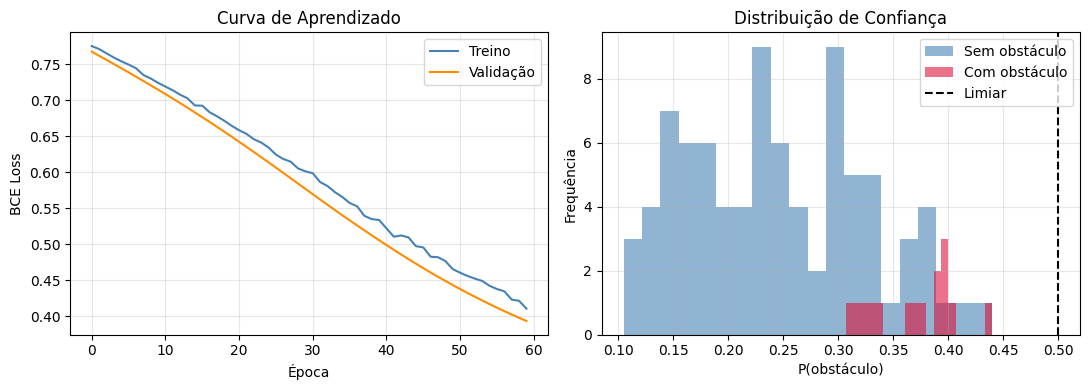

In [4]:
# ═══════════════════════════════════════════════════════════
# MINI-TREINO — Demonstração completa do ciclo IA em ~30s
# Coleta (simulada) → Treino → Inferência no nó ROS 2
# ═══════════════════════════════════════════════════════════
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# ── 1. Gerar dataset sintético ─────────────────────────────
np.random.seed(42)
N = 500

# Features: [vel_x, vel_y, dist_scan, ang_vel]
# Label: 1 = obstáculo detectado (dist_scan < 0.5m)
vel_x    = np.random.uniform(-0.5, 0.5, N)
vel_y    = np.random.uniform(-0.1, 0.1, N)
dist     = np.random.uniform(0.1, 3.0, N)
ang_vel  = np.random.uniform(-1.0, 1.0, N)
labels   = (dist < 0.5).astype(float)

X = np.column_stack([vel_x, vel_y, dist, ang_vel]).astype(np.float32)
y = labels.astype(np.float32).reshape(-1, 1)

# Normalizar (salvar escaler para inferência)
X_mean, X_std = X.mean(0), X.std(0)
X_norm = (X - X_mean) / (X_std + 1e-8)

# Split treino/validação
split = int(0.8 * N)
X_tr, X_vl = torch.FloatTensor(X_norm[:split]), torch.FloatTensor(X_norm[split:])
y_tr, y_vl = torch.FloatTensor(y[:split]),      torch.FloatTensor(y[split:])

print(f'Dataset: {N} amostras | Treino: {split} | Val: {N-split}')
print(f'Obstáculos: {int(labels.sum())} ({labels.mean()*100:.0f}%)')

# ── 2. Definir modelo ObstacleNet ─────────────────────────
class ObstacleNet(nn.Module):
    """MLP 4→32→16→1 para detecção binária de obstáculos."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 32), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1),  nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

model     = ObstacleNet()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCELoss()

# ── 3. Treinar ─────────────────────────────────────────────
EPOCHS = 60
losses_tr, losses_vl = [], []

for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()
    pred = model(X_tr)
    loss = criterion(pred, y_tr)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        vl_loss = criterion(model(X_vl), y_vl).item()
    losses_tr.append(loss.item())
    losses_vl.append(vl_loss)

    if (epoch + 1) % 15 == 0:
        print(f'Epoch {epoch+1:3d}/{EPOCHS} | '
              f'loss={loss.item():.4f} | val={vl_loss:.4f}')

# ── 4. Avaliar ─────────────────────────────────────────────
model.eval()
with torch.no_grad():
    preds = (model(X_vl) > 0.5).float()
    acc = (preds == y_vl).float().mean().item()

print(f'\n✅ Acurácia na validação: {acc*100:.1f}%')

# ── 5. Salvar modelo ──────────────────────────────────────
import json, os
os.makedirs('models', exist_ok=True)
torch.save(model.state_dict(), 'models/obstacle_net_v1.pt')
json.dump({'mean': X_mean.tolist(), 'std': X_std.tolist()},
          open('models/scaler_config.json', 'w'))

print('📦 Modelo salvo: models/obstacle_net_v1.pt')
print('📦 Scaler: models/scaler_config.json')

# ── 6. Plotar curva de aprendizado ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(losses_tr, label='Treino', color='steelblue')
axes[0].plot(losses_vl, label='Validação', color='darkorange')
axes[0].set(title='Curva de Aprendizado', xlabel='Época', ylabel='BCE Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Distribuição de confiança
with torch.no_grad():
    probs = model(X_vl).numpy().flatten()
axes[1].hist(probs[y_vl.numpy().flatten()==0], bins=20,
             alpha=0.6, color='steelblue', label='Sem obstáculo')
axes[1].hist(probs[y_vl.numpy().flatten()==1], bins=20,
             alpha=0.6, color='crimson', label='Com obstáculo')
axes[1].axvline(0.5, color='k', ls='--', lw=1.5, label='Limiar')
axes[1].set(title='Distribuição de Confiança', xlabel='P(obstáculo)', ylabel='Frequência')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('treino_resultado.png', dpi=120)
plt.show()

In [5]:
# ═══════════════════════════════════════════════════════════
# INFERÊNCIA EM NÓ ROS 2 — Carregar modelo e inferir ao vivo
# ═══════════════════════════════════════════════════════════
import json, torch
from rclpy.node import Node
from std_msgs.msg import Bool, Float32

# Carregar scaler
cfg = json.load(open('models/scaler_config.json'))
mean_t = torch.FloatTensor(cfg['mean'])
std_t  = torch.FloatTensor(cfg['std'])

# Carregar modelo
model_inf = ObstacleNet()
model_inf.load_state_dict(torch.load('models/obstacle_net_v1.pt', weights_only=True))
model_inf.eval()
print('✅ Modelo carregado para inferência')

# Testar com amostras sintéticas
print('\n=== Teste de Inferência ===' )
print(f'{"vel_x":>6} {"vel_y":>6} {"dist":>6} {"ang":>6} | {"P(obs)":>7} | {"Decisão"}')
print('-' * 55)

testes = [
    ( 0.3,  0.0, 0.2,  0.0, 'OBSTÁCULO PERTO'),
    ( 0.3,  0.0, 1.5,  0.0, 'Caminho livre'),
    ( 0.0,  0.0, 0.35, 0.5, 'OBSTÁCULO PERTO'),
    (-0.2,  0.0, 2.0, -0.3, 'Caminho livre'),
    ( 0.1,  0.0, 0.48, 0.1, 'OBSTÁCULO PERTO'),
]

for vx, vy, d, av, esperado in testes:
    feat = torch.FloatTensor([[vx, vy, d, av]])
    norm = (feat - mean_t) / (std_t + 1e-8)
    with torch.no_grad():
        prob = model_inf(norm).item()
    detectado = 'OBSTÁCULO' if prob > 0.5 else 'livre'
    ok = '✅' if detectado.lower() in esperado.lower() else '❌'
    print(f'{vx:6.2f} {vy:6.2f} {d:6.2f} {av:6.2f} | {prob:7.3f} | {detectado} {ok}')

print('\n🚀 Modelo pronto para embarcar em nó ROS 2!')
print('   Próximo passo: git commit + git push + colcon build')

✅ Modelo carregado para inferência

=== Teste de Inferência ===
 vel_x  vel_y   dist    ang |  P(obs) | Decisão
-------------------------------------------------------
  0.30   0.00   0.20   0.00 |   0.411 | livre ❌
  0.30   0.00   1.50   0.00 |   0.322 | livre ✅
  0.00   0.00   0.35   0.50 |   0.449 | livre ❌
 -0.20   0.00   2.00  -0.30 |   0.316 | livre ✅
  0.10   0.00   0.48   0.10 |   0.433 | livre ❌

🚀 Modelo pronto para embarcar em nó ROS 2!
   Próximo passo: git commit + git push + colcon build
